# Lab 7: Geometric Transformations, Camera Calibration & 3D Reconstruction

In [1]:
import os, glob, urllib.request
import numpy as np
import cv2
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d.art3d import Poly3DCollection

print("OpenCV", cv2.__version__, "| NumPy", np.__version__)
os.makedirs("images/castle", exist_ok=True)

OPENCV_RAW = "https://raw.githubusercontent.com/opencv/opencv/4.x/samples/data/"
CASTLE_RAW = "https://raw.githubusercontent.com/openMVG/ImageDataset_SceauxCastle/master/images/"

def fetch(url, path):
    # download once; reuse the local copy afterwards
    if not os.path.exists(path):
        urllib.request.urlretrieve(url, path)
    return path

for name in ["messi5.jpg", "sudoku.png", "building.jpg"] + \
            [f"left{i:02d}.jpg" for i in (1,2,3,4,5,6,7,8,9,11,12,13,14)]:
    fetch(OPENCV_RAW + name, f"images/{name}")
for name in [f"100_71{i:02d}.JPG" for i in range(0, 11)] + ["K.txt"]:
    fetch(CASTLE_RAW + name, f"images/castle/{name}")
print(len(glob.glob("images/*")), "files in images/,", len(glob.glob("images/castle/*.JPG")), "castle photos")

def show(imgs, titles, cols=None, size=4, aspect=0.8):
    cols = cols or len(imgs)
    rows = int(np.ceil(len(imgs) / cols))
    fig, ax = plt.subplots(rows, cols, figsize=(size*cols, size*rows*aspect))
    ax = np.atleast_1d(ax).ravel()
    for a in ax: a.axis("off")
    for a, im, t in zip(ax, imgs, titles):
        a.imshow(im if im.ndim == 2 else cv2.cvtColor(im, cv2.COLOR_BGR2RGB), cmap="gray")
        a.set_title(t)
    plt.tight_layout(); plt.show()

OpenCV 5.0.0 | NumPy 2.5.3
18 files in images/, 11 castle photos


---
# Q1: Image Transformations
## (a) 2D transformations — translation, rotation, scaling, shearing

Image size: 548 x 342
Translation:
[[  1.   0. 100.]
 [  0.   1.  50.]]

Rotation:
[[  0.866   0.5   -48.791]
 [ -0.5     0.866 159.91 ]]

Scaling:
[[0.6 0.  0. ]
 [0.  0.6 0. ]]

Shear:
[[1.  0.3 0. ]
 [0.2 1.  0. ]]



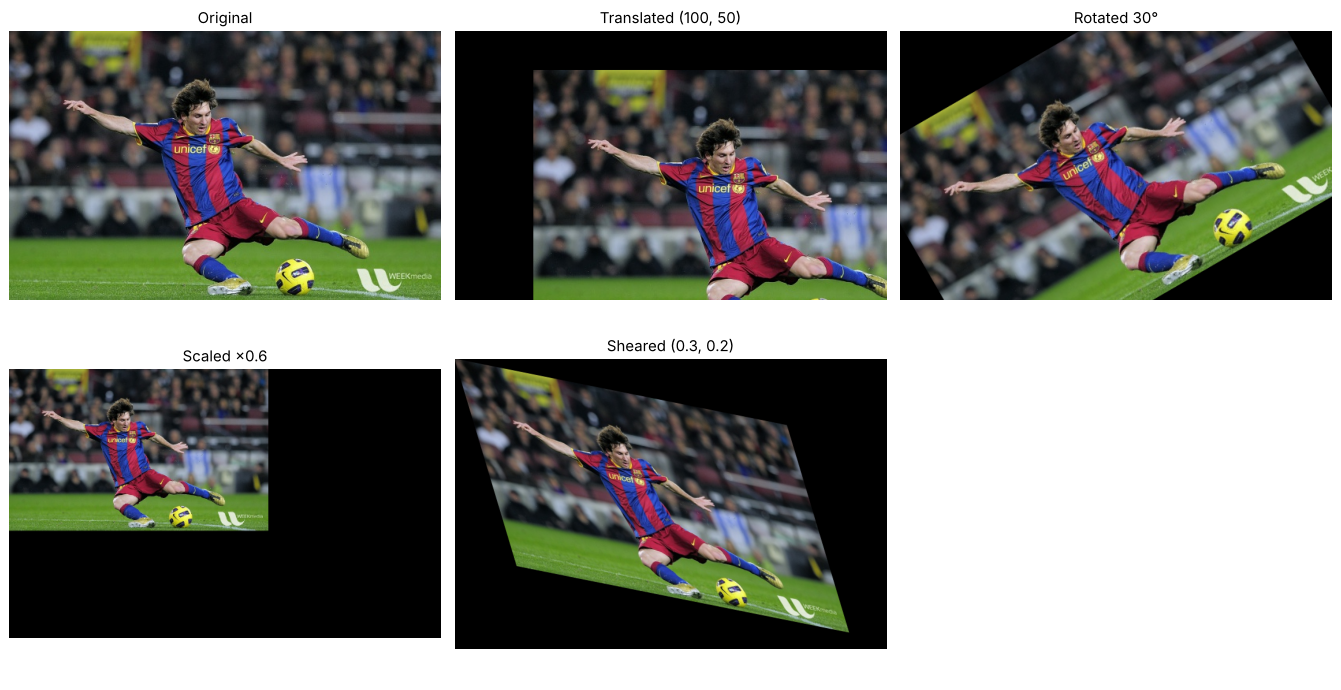

In [2]:
img = cv2.imread("images/messi5.jpg")
h, w = img.shape[:2]
print("Image size:", w, "x", h)

T_trans = np.float32([[1, 0, 100], [0, 1, 50]])                  # move right 100, down 50
T_rot   = cv2.getRotationMatrix2D((w/2, h/2), 30, 1.0)            # 30° CCW about centre
T_scale = np.float32([[0.6, 0, 0], [0, 0.6, 0]])                 # shrink to 60 %
T_shear = np.float32([[1, 0.3, 0], [0.2, 1, 0]])                 # shear in x and y

translated = cv2.warpAffine(img, T_trans, (w, h))
rotated    = cv2.warpAffine(img, T_rot,   (w, h))
scaled     = cv2.warpAffine(img, T_scale, (w, h))
sheared    = cv2.warpAffine(img, T_shear, (int(w*1.3), int(h*1.4)))

for n, M in [("Translation", T_trans), ("Rotation", T_rot), ("Scaling", T_scale), ("Shear", T_shear)]:
    print(f"{n}:\n{np.round(M, 3)}\n")
show([img, translated, rotated, scaled, sheared],
     ["Original", "Translated (100, 50)", "Rotated 30°", "Scaled ×0.6", "Sheared (0.3, 0.2)"], cols=3, size=5)

## (b) 3D transformation: rotating / moving a cube along x, y, z

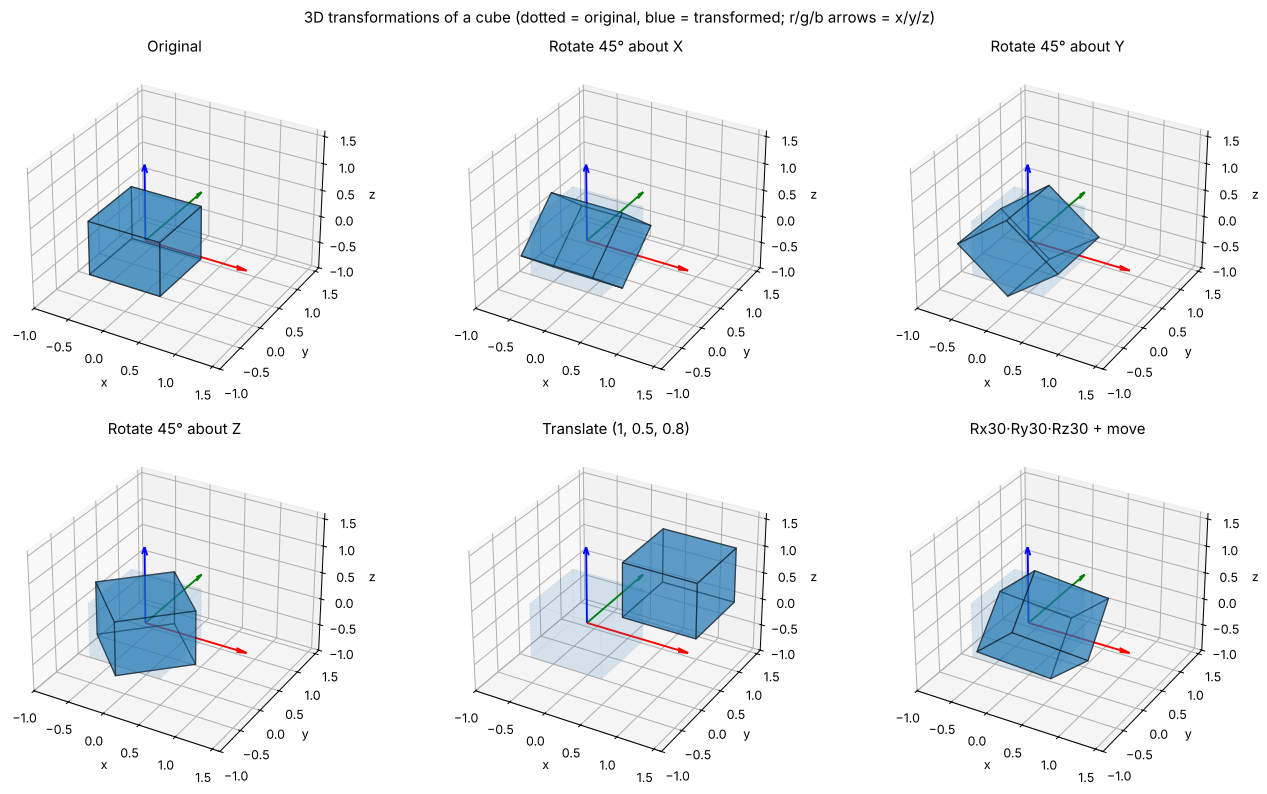

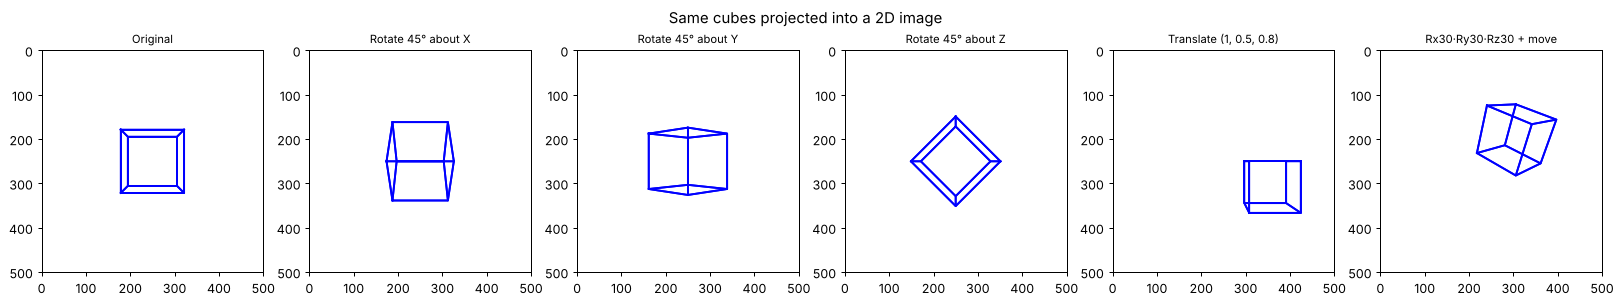

In [ ]:
cube = np.array([[x, y, z] for x in (0, 1) for y in (0, 1) for z in (0, 1)], float) - 0.5
faces = [[0,1,3,2], [4,5,7,6], [0,1,5,4], [2,3,7,6], [0,2,6,4], [1,3,7,5]]

def Rx(a): a=np.radians(a); return np.array([[1,0,0],[0,np.cos(a),-np.sin(a)],[0,np.sin(a),np.cos(a)]])
def Ry(a): a=np.radians(a); return np.array([[np.cos(a),0,np.sin(a)],[0,1,0],[-np.sin(a),0,np.cos(a)]])
def Rz(a): a=np.radians(a); return np.array([[np.cos(a),-np.sin(a),0],[np.sin(a),np.cos(a),0],[0,0,1]])

def H(R=np.eye(3), t=(0,0,0)):
    M = np.eye(4); M[:3,:3] = R; M[:3,3] = t; return M

def apply(M, P):
    Ph = np.hstack([P, np.ones((len(P),1))])      # to homogeneous
    return (M @ Ph.T).T[:, :3]

cases = {
    "Original":               H(),
    "Rotate 45° about X":     H(Rx(45)),
    "Rotate 45° about Y":     H(Ry(45)),
    "Rotate 45° about Z":     H(Rz(45)),
    "Translate (1, 0.5, 0.8)": H(t=(1, .5, .8)),
    "Rx30·Ry30·Rz30 + move":  H(Rz(30)@Ry(30)@Rx(30), (0.5, -0.5, 0.5)),
}
fig = plt.figure(figsize=(15, 9))
for k, (name, M) in enumerate(cases.items()):
    P = apply(M, cube)
    ax = fig.add_subplot(2, 3, k+1, projection="3d")
    ax.add_collection3d(Poly3DCollection([cube[f] for f in faces], alpha=.08, edgecolor="gray", linestyle=":"))
    ax.add_collection3d(Poly3DCollection([P[f] for f in faces], alpha=.45, facecolor="tab:blue", edgecolor="k"))
    for v, c in zip(np.eye(3), "rgb"):
        ax.quiver(0, 0, 0, *v*1.4, color=c, arrow_length_ratio=.1)
    ax.set_xlim(-1, 1.6); ax.set_ylim(-1, 1.6); ax.set_zlim(-1, 1.6)
    ax.set_xlabel("x"); ax.set_ylabel("y"); ax.set_zlabel("z"); ax.set_title(name)
plt.suptitle("3D transformations of a cube (dotted = original, blue = transformed; r/g/b arrows = x/y/z)")
plt.tight_layout(); plt.show()

K = np.array([[500, 0, 250], [0, 500, 250], [0, 0, 1.]])
fig, axs = plt.subplots(1, 6, figsize=(18, 3.2))
for ax, (name, M) in zip(axs, cases.items()):
    P = apply(M, cube) + [0, 0, 4]
    p = (K @ P.T).T; p = p[:, :2] / p[:, 2:]
    for f in faces:
        q = p[f + [f[0]]]; ax.plot(q[:,0], q[:,1], "b-")
    ax.set_xlim(0, 500); ax.set_ylim(500, 0); ax.set_aspect("equal"); ax.set_title(name, fontsize=9)
plt.suptitle("Same cubes projected into a 2D image"); plt.tight_layout(); plt.show()

## (c) Homogeneous coordinates

In [4]:
p = np.array([3, 4])
p_h = np.append(p, 1)                         # (3, 4) -> (3, 4, 1)
print("Cartesian point       :", p)
print("Homogeneous point     :", p_h)
print("Same point scaled ×5  :", 5 * p_h, "-> back to Cartesian:", (5*p_h)[:2] / (5*p_h)[2])

# Translation is NOT linear in 2D, but it IS a matrix product in homogeneous coords
T = np.array([[1, 0, 10], [0, 1, -2], [0, 0, 1]])
R = np.array([[0, -1, 0], [1, 0, 0], [0, 0, 1]])          # rotate 90°
S = np.diag([2, 2, 1])                                     # scale ×2
print("\nTranslate by (10,-2)  :", T @ p_h)
M = T @ R @ S                                               # chain: scale -> rotate -> translate
print("Composite T·R·S matrix:\n", M)
print("Composite applied     :", M @ p_h)

# Projective transforms produce W != 1 -> divide to get pixel position
Hm = np.array([[1, 0.2, 5], [0.1, 1, 3], [0.001, 0.002, 1]])
q = Hm @ p_h
print("\nHomography result     :", np.round(q, 4), "-> pixel", np.round(q[:2]/q[2], 3))

# Points at infinity (W = 0) = directions; the intersection of two parallel lines
l1 = np.cross([0, 0, 1], [1, 1, 1])     # line through (0,0) and (1,1)
l2 = np.cross([0, 1, 1], [1, 2, 1])     # parallel line through (0,1) and (1,2)
print("Intersection of parallel lines:", np.cross(l1, l2), " (W=0 -> point at infinity)")

Cartesian point       : [3 4]
Homogeneous point     : [3 4 1]
Same point scaled ×5  : [15 20  5] -> back to Cartesian: [3. 4.]

Translate by (10,-2)  : [13  2  1]
Composite T·R·S matrix:
 [[ 0 -2 10]
 [ 2  0 -2]
 [ 0  0  1]]
Composite applied     : [2 4 1]

Homography result     : [8.8   7.3   1.011] -> pixel [8.704 7.221]
Intersection of parallel lines: [-1 -1  0]  (W=0 -> point at infinity)


## (d) Affine transformation — do straight lines stay straight?

Affine matrix:
 [[ 7.509e-01  2.174e-01  8.680e+01]
 [-1.038e-01  7.012e-01  1.200e+02]]

Line                        max deviation from straight line (px)
(50, 60)->(818, 60)          2.17e-14
(50, 200)->(818, 200)        1.41e-14
(80, 30)->(80, 570)          5.06e-14
(300, 30)->(300, 570)        2.13e-14
(40, 560)->(828, 40)         3.47e-14

Angles after warp (deg): [ -7.871  -7.871  72.777  72.777 -43.004]
Horizontal pair still parallel: True | vertical pair still parallel: True

Projective warp angles   : [  0.      0.    108.148  97.073] -> vertical pair no longer parallel


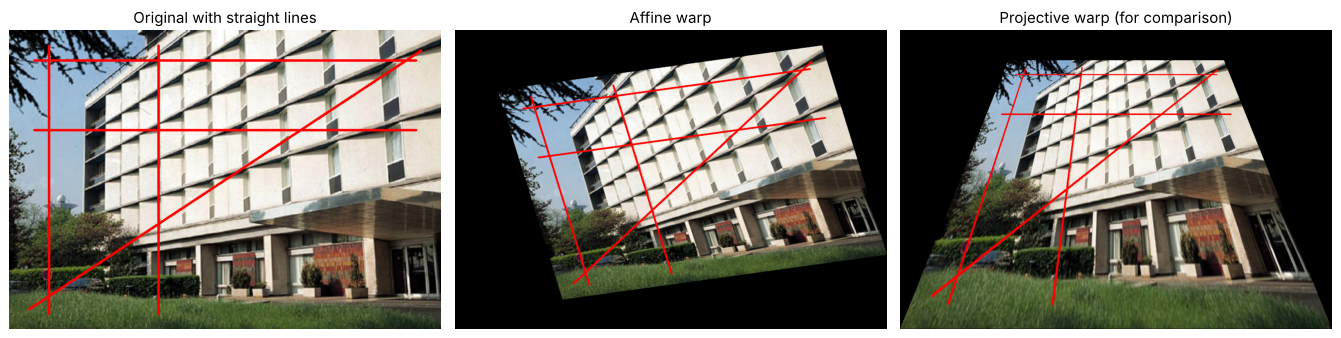

In [5]:
img = cv2.imread("images/building.jpg")
h, w = img.shape[:2]
drawn = img.copy()
lines = [((50, 60), (w-50, 60)), ((50, 200), (w-50, 200)),          # two parallel horizontals
         ((80, 30), (80, h-30)), ((300, 30), (300, h-30)),           # two parallel verticals
         ((40, h-40), (w-40, 40))]                                     # a diagonal
for a, b in lines:
    cv2.line(drawn, a, b, (0, 0, 255), 3)

src = np.float32([[0, 0], [w-1, 0], [0, h-1]])
dst = np.float32([[w*0.10, h*0.20], [w*0.85, h*0.05], [w*0.25, h*0.90]])
A = cv2.getAffineTransform(src, dst)
affine = cv2.warpAffine(drawn, A, (w, h))
print("Affine matrix:\n", np.round(A, 4))

def tf(M, pts):                                 # apply 2x3 or 3x3 matrix to Nx2 points
    M3 = np.vstack([M, [0, 0, 1]]) if M.shape[0] == 2 else M
    q = (M3 @ np.c_[pts, np.ones(len(pts))].T).T
    return q[:, :2] / q[:, 2:]

def collinearity_error(pts):                    # max distance of points from best-fit line
    c = pts - pts.mean(0)
    return np.linalg.svd(c, full_matrices=False)[1][-1] / np.sqrt(len(pts))

print("\nLine                        max deviation from straight line (px)")
dirs = []
for a, b in lines:
    pts = np.linspace(a, b, 50)
    q = tf(A, pts)
    d = q[-1] - q[0]; dirs.append(np.degrees(np.arctan2(d[1], d[0])))
    print(f"{str(a)+'->'+str(b):28s} {collinearity_error(q):.2e}")
print("\nAngles after warp (deg):", np.round(dirs, 3))
print("Horizontal pair still parallel:", np.isclose(dirs[0], dirs[1]),
      "| vertical pair still parallel:", np.isclose(dirs[2], dirs[3]))

# compare with a projective warp, where lines stay straight but parallelism breaks
Hp = cv2.getPerspectiveTransform(np.float32([[0,0],[w,0],[w,h],[0,h]]),
                                 np.float32([[w*.25,h*.1],[w*.75,h*.1],[w,h],[0,h]]))
persp = cv2.warpPerspective(drawn, Hp, (w, h))
pd = []
for a, b in lines[:4]:
    q = tf(Hp, np.linspace(a, b, 50)); d = q[-1]-q[0]; pd.append(np.degrees(np.arctan2(d[1], d[0])))
print("\nProjective warp angles   :", np.round(pd, 3), "-> vertical pair no longer parallel")
show([drawn, affine, persp], ["Original with straight lines", "Affine warp", "Projective warp (for comparison)"], size=5)

## (e) Projective transformation (homography) — make a slanted page look flat

Corners found: 4
Source corners:
 [[ 73.  84.]
 [492.  69.]
 [519. 522.]
 [ 34. 516.]] 
Homography:
 [[ 1.1721600e+00  1.0582000e-01 -9.4456350e+01]
 [ 4.4880000e-02  1.2536900e+00 -1.0858591e+02]
 [ 1.3000000e-04  3.8000000e-04  1.0000000e+00]]


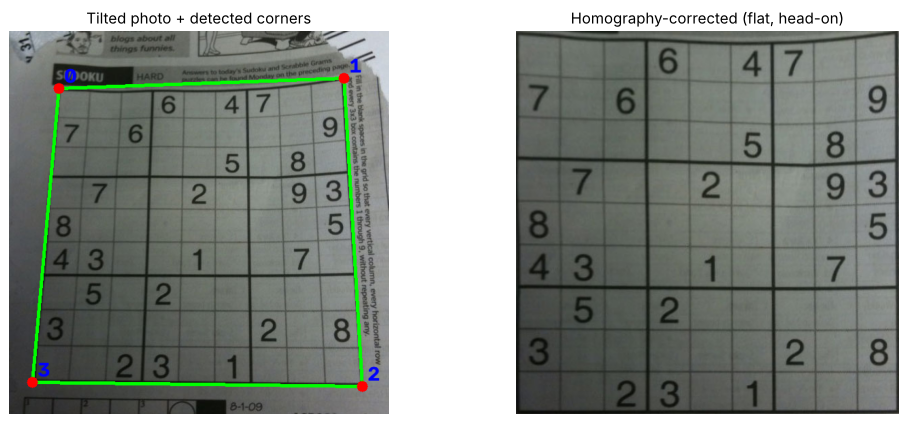

In [6]:
img = cv2.imread("images/sudoku.png")
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
th = cv2.adaptiveThreshold(cv2.GaussianBlur(gray, (7, 7), 0), 255,
                           cv2.ADAPTIVE_THRESH_GAUSSIAN_C, cv2.THRESH_BINARY_INV, 11, 2)
cnts, _ = cv2.findContours(th, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
page = max(cnts, key=cv2.contourArea)
quad = cv2.approxPolyDP(page, 0.02 * cv2.arcLength(page, True), True).reshape(-1, 2).astype(np.float32)
print("Corners found:", len(quad))

def order_corners(p):                       # top-left, top-right, bottom-right, bottom-left
    s, d = p.sum(1), np.diff(p, axis=1).ravel()
    return np.float32([p[np.argmin(s)], p[np.argmin(d)], p[np.argmax(s)], p[np.argmax(d)]])

src = order_corners(quad)
side = 450
dst = np.float32([[0, 0], [side-1, 0], [side-1, side-1], [0, side-1]])
Hm = cv2.getPerspectiveTransform(src, dst)
flat = cv2.warpPerspective(img, Hm, (side, side))
print("Source corners:\n", src, "\nHomography:\n", np.round(Hm, 5))

vis = img.copy()
cv2.polylines(vis, [src.astype(int)], True, (0, 255, 0), 3)
for i, (x, y) in enumerate(src.astype(int)):
    cv2.circle(vis, (x, y), 8, (0, 0, 255), -1); cv2.putText(vis, str(i), (x+8, y-8), 0, 1, (255, 0, 0), 2)
show([vis, flat], ["Tilted photo + detected corners", "Homography-corrected (flat, head-on)"], size=6)

---
# Q2. Perspective Correction (Unwarping)

Forward H:
 [[ 4.928e-01 -2.253e-01  9.864e+01]
 [-6.570e-02  5.183e-01  4.104e+01]
 [-5.000e-04 -6.000e-04  1.000e+00]]
Inverse H:
 [[ 2.256000e+00  6.911000e-01 -2.508886e+02]
 [ 1.940000e-01  2.237900e+00 -1.109786e+02]
 [ 1.200000e-03  1.700000e-03  1.000000e+00]]
H_inv · H_fwd (normalised) ≈ I:
 [[ 1.  0.  0.]
 [ 0.  1.  0.]
 [-0.  0.  1.]]
H_inv equals inv(H_fwd): True
PSNR original vs recovered: 34.03 dB (loss only from resampling the smaller tilted image)


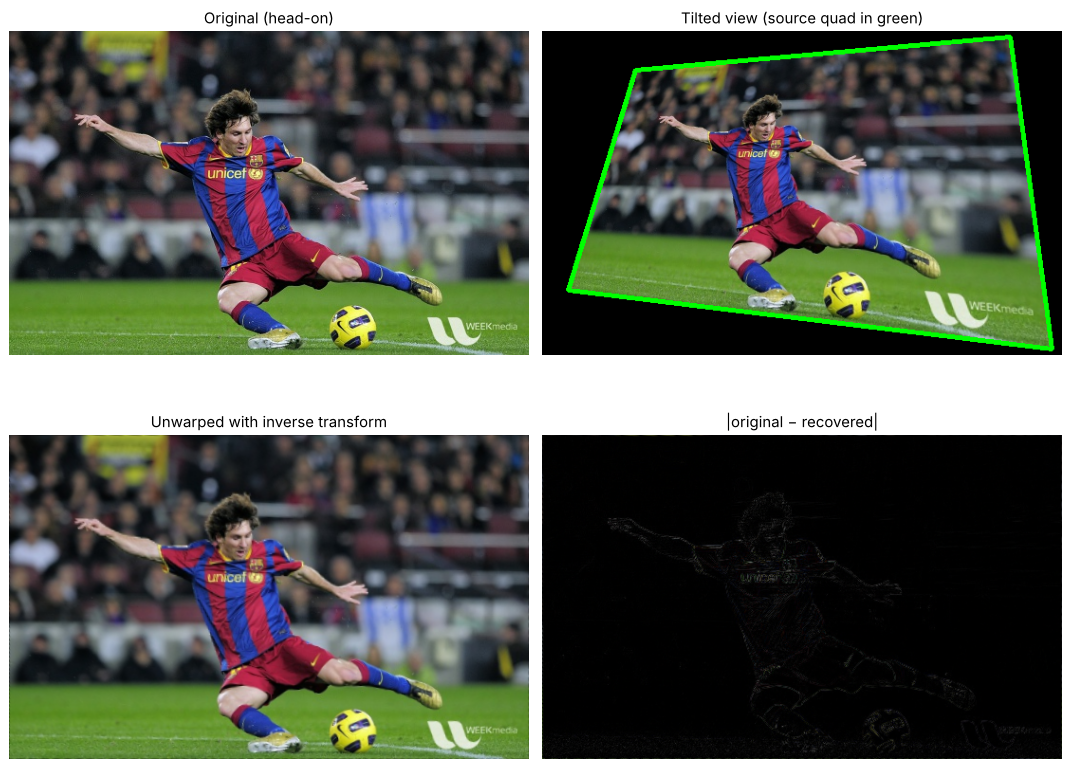

In [7]:
def apply_perspective_transform(image, src_pts, dst_pts, size):
    # Compute the homography src->dst and warp the image onto a canvas of `size` (w, h)
    H = cv2.getPerspectiveTransform(np.float32(src_pts), np.float32(dst_pts))
    return cv2.warpPerspective(image, H, size), H

flat = cv2.imread("images/messi5.jpg")
h, w = flat.shape[:2]
rect = np.float32([[0, 0], [w-1, 0], [w-1, h-1], [0, h-1]])                       # perfect rectangle
tilted_quad = np.float32([[0.18*w, 0.12*h], [0.90*w, 0.02*h], [0.98*w, 0.98*h], [0.05*w, 0.80*h]])

# 1) Forward: rectangle -> tilted view
tilted, H_fwd = apply_perspective_transform(flat, rect, tilted_quad, (w, h))

# 2) Inverse: tilted view as SOURCE, perfect rectangle as DESTINATION (inputs swapped)
recovered, H_inv = apply_perspective_transform(tilted, tilted_quad, rect, (w, h))

print("Forward H:\n", np.round(H_fwd, 4))
print("Inverse H:\n", np.round(H_inv, 4))
print("H_inv · H_fwd (normalised) ≈ I:\n", np.round((H_inv @ H_fwd) / (H_inv @ H_fwd)[2, 2], 6))
print("H_inv equals inv(H_fwd):", np.allclose(H_inv / H_inv[2,2], np.linalg.inv(H_fwd) / np.linalg.inv(H_fwd)[2,2]))

mask = np.ones((h, w), np.uint8); mask[:5] = mask[-5:] = 0; mask[:, :5] = mask[:, -5:] = 0
psnr = cv2.PSNR(flat * mask[..., None], recovered * mask[..., None])
print(f"PSNR original vs recovered: {psnr:.2f} dB (loss only from resampling the smaller tilted image)")

vis = tilted.copy(); cv2.polylines(vis, [tilted_quad.astype(int)], True, (0, 255, 0), 3)
diff = cv2.absdiff(flat, recovered)
show([flat, vis, recovered, diff], ["Original (head-on)", "Tilted view (source quad in green)",
                                     "Unwarped with inverse transform", "|original − recovered|"], cols=2, size=6)

---
# Q3. Undistort Live Camera Feed

Used 13/13 images
RMS re-projection error: 0.4087 px
Camera matrix K:
 [[536.073   0.    342.37 ]
 [  0.    536.016 235.537]
 [  0.      0.      1.   ]]
Distortion coeffs [k1 k2 p1 p2 k3]: [-0.26509 -0.04674  0.00183 -0.00031  0.25231]
Mean per-image error: 0.2346 px
Saved -> /home/claude/lab07/camera_calib.npz


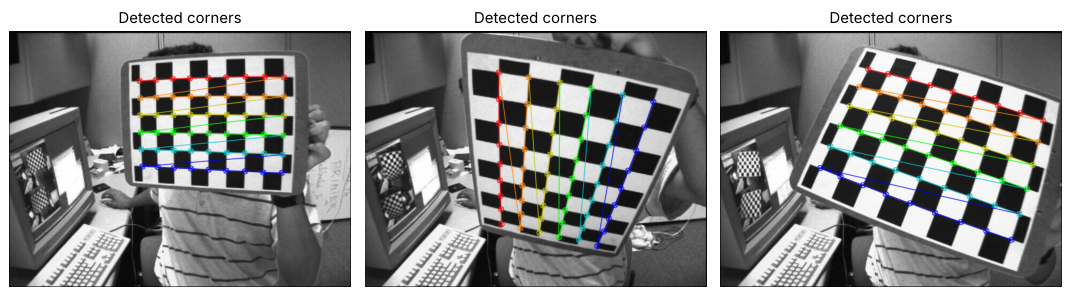

In [8]:
pattern = (9, 6)                      # inner corners per row, per column
square = 1.0                          # square size (any unit; only scales the extrinsics)
objp = np.zeros((pattern[0]*pattern[1], 3), np.float32)
objp[:, :2] = np.mgrid[0:pattern[0], 0:pattern[1]].T.reshape(-1, 2) * square

def calibrate(image_paths, pattern=pattern, save_to="camera_calib.npz"):
    obj_pts, img_pts, shown, size = [], [], [], None
    crit = (cv2.TERM_CRITERIA_EPS + cv2.TERM_CRITERIA_MAX_ITER, 30, 1e-3)
    for p in image_paths:
        g = cv2.imread(p, cv2.IMREAD_GRAYSCALE); size = g.shape[::-1]
        ok, c = cv2.findChessboardCorners(g, pattern, None)
        if not ok: print("  no board:", p); continue
        c = cv2.cornerSubPix(g, c, (11, 11), (-1, -1), crit)
        obj_pts.append(objp); img_pts.append(c)
        if len(shown) < 3:
            v = cv2.cvtColor(g, cv2.COLOR_GRAY2BGR); cv2.drawChessboardCorners(v, pattern, c, ok); shown.append(v)
    rms, K, dist, rvecs, tvecs = cv2.calibrateCamera(obj_pts, img_pts, size, None, None)
    np.savez(save_to, camera_matrix=K, dist_coeffs=dist, image_size=size, rms=rms)
    return rms, K, dist, rvecs, tvecs, obj_pts, img_pts, shown

paths = sorted(glob.glob("images/left*.jpg"))
rms, K, dist, rvecs, tvecs, obj_pts, img_pts, shown = calibrate(paths)
print(f"Used {len(img_pts)}/{len(paths)} images")
print(f"RMS re-projection error: {rms:.4f} px")
print("Camera matrix K:\n", np.round(K, 3))
print("Distortion coeffs [k1 k2 p1 p2 k3]:", np.round(dist.ravel(), 5))

errs = [np.linalg.norm(ip.reshape(-1, 2) - cv2.projectPoints(op, r, t, K, dist)[0].reshape(-1, 2), axis=1).mean()
        for op, ip, r, t in zip(obj_pts, img_pts, rvecs, tvecs)]
print("Mean per-image error: %.4f px" % np.mean(errs))
print("Saved ->", os.path.abspath("camera_calib.npz"))
show(shown, ["Detected corners"]*3, size=4)

### Step 2 — Load the saved parameters and undistort with cv2.undistort()

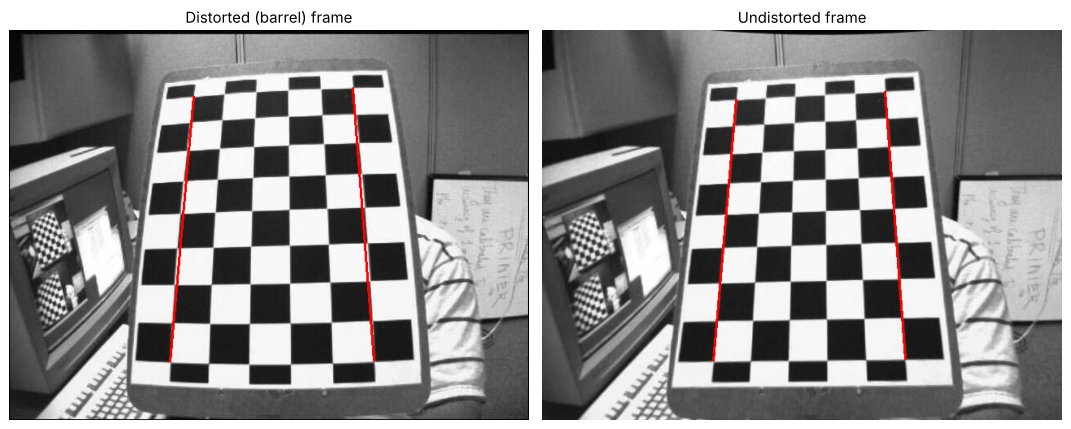

In [9]:
calib = np.load("camera_calib.npz")
K, dist = calib["camera_matrix"], calib["dist_coeffs"]

def undistort_frame(frame, K, dist, alpha=0):
    h, w = frame.shape[:2]
    newK, roi = cv2.getOptimalNewCameraMatrix(K, dist, (w, h), alpha, (w, h))
    und = cv2.undistort(frame, K, dist, None, newK)
    x, y, rw, rh = roi
    return und[y:y+rh, x:x+rw] if rw > 0 and rh > 0 else und

frame = cv2.imread("images/left12.jpg")
und = undistort_frame(frame, K, dist)
# draw straight reference lines through outer chessboard corners to show the curvature removal
def overlay(img):
    g = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    ok, c = cv2.findChessboardCorners(g, pattern)
    v = img.copy()
    if ok:
        c = c.reshape(pattern[1], pattern[0], 2)
        for row in (c[0], c[-1]): cv2.line(v, tuple(row[0].astype(int)), tuple(row[-1].astype(int)), (0, 0, 255), 2)
    return v
show([overlay(frame), overlay(und)], ["Distorted (barrel) frame", "Undistorted frame"], size=6)

### Step 3 — Real-time undistortion of the webcam with cv2.VideoCapture()

No webcam available here -> running the same loop on a simulated feed.
cv2.undistort: 2.91 ms/frame -> ~343 FPS possible at 640x480


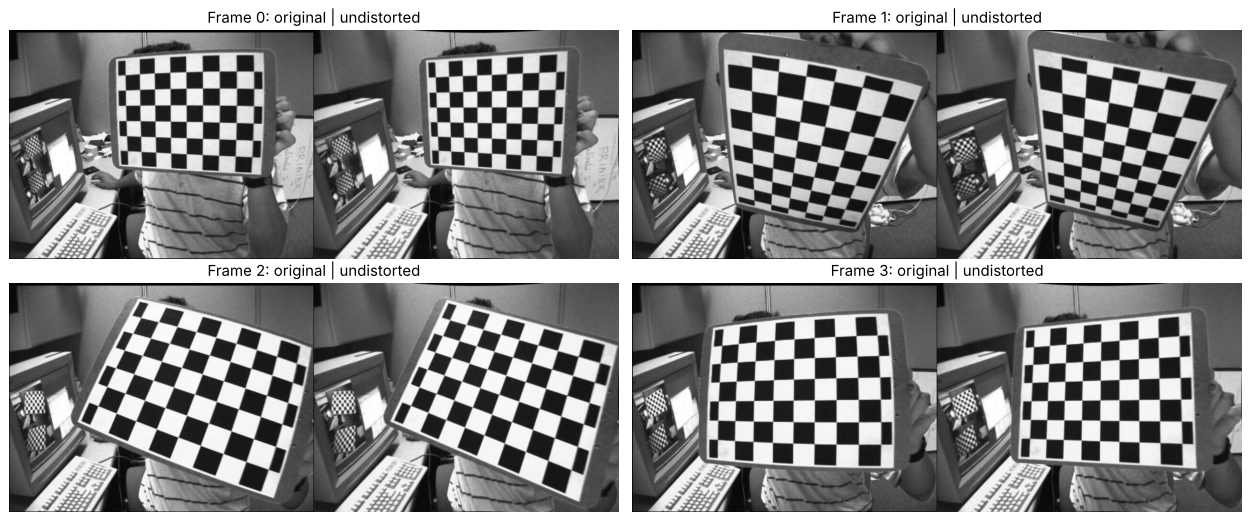

In [10]:
import time

def capture_calibration_frames(n=15, cam=0, out_dir="my_calib"):
    os.makedirs(out_dir, exist_ok=True)
    cap, k = cv2.VideoCapture(cam), 0
    while k < n:
        ok, f = cap.read()
        if not ok: break
        found, c = cv2.findChessboardCorners(cv2.cvtColor(f, cv2.COLOR_BGR2GRAY), pattern)
        v = f.copy(); cv2.drawChessboardCorners(v, pattern, c, found) if found else None
        cv2.imshow("press c to capture, q to quit", v)
        key = cv2.waitKey(1) & 0xFF
        if key == ord("c") and found: cv2.imwrite(f"{out_dir}/{k:02d}.jpg", f); k += 1; print("captured", k)
        if key == ord("q"): break
    cap.release(); cv2.destroyAllWindows()
    # then: calibrate(sorted(glob.glob(out_dir + '/*.jpg')))

def live_undistort(calib_file="camera_calib.npz", cam=0):
    d = np.load(calib_file); K, dist = d["camera_matrix"], d["dist_coeffs"]
    cap = cv2.VideoCapture(cam)
    if not cap.isOpened():
        return False
    newK = None
    while True:
        ok, frame = cap.read()
        if not ok: break
        if newK is None:
            h, w = frame.shape[:2]
            newK, _ = cv2.getOptimalNewCameraMatrix(K, dist, (w, h), 0, (w, h))
        und = cv2.undistort(frame, K, dist, None, newK)          # real-time undistortion
        cv2.imshow("Original | Undistorted  (q to quit)", np.hstack([frame, und]))
        if cv2.waitKey(1) & 0xFF == ord("q"): break
    cap.release(); cv2.destroyAllWindows()
    return True

if not live_undistort():
    print("No webcam available here -> running the same loop on a simulated feed.")
    frames = [cv2.imread(p) for p in paths[:6]]
    h, w = frames[0].shape[:2]
    newK, _ = cv2.getOptimalNewCameraMatrix(K, dist, (w, h), 0, (w, h))
    times, pairs = [], []
    for f in frames:
        t = time.perf_counter()
        und = cv2.undistort(f, K, dist, None, newK)
        times.append((time.perf_counter() - t) * 1000)
        pairs.append(np.hstack([f, und]))
    print(f"cv2.undistort: {np.mean(times):.2f} ms/frame -> ~{1000/np.mean(times):.0f} FPS possible at {w}x{h}")
    show(pairs[:4], [f"Frame {i}: original | undistorted" for i in range(4)], cols=2, size=7, aspect=0.42)

---
# Q4. Build a 3D Model from Images Using COLMAP

In [11]:
try:
    import pycolmap
    HAVE_COLMAP = True
except ImportError:
    HAVE_COLMAP = False
print("pycolmap available:", HAVE_COLMAP)

if HAVE_COLMAP:
    from pathlib import Path
    out = Path("colmap_out"); out.mkdir(exist_ok=True)
    db = out / "database.db"
    if db.exists(): db.unlink()
    pycolmap.extract_features(db, "images/castle")                 # 1) detect SIFT features
    pycolmap.match_exhaustive(db)                                  # 2) match across images
    maps = pycolmap.incremental_mapping(db, "images/castle", out)  # 3) camera poses + sparse points
    rec = maps[0]
    print(rec.summary())
    rec.export_PLY(str(out / "castle_sparse.ply"))                 # 4) point cloud
    try:
        import open3d as o3d                                        # 4b) mesh from the point cloud
        pcd = o3d.io.read_point_cloud(str(out / "castle_sparse.ply")); pcd.estimate_normals()
        mesh, _ = o3d.geometry.TriangleMesh.create_from_point_cloud_poisson(pcd, depth=8)
        o3d.io.write_triangle_mesh(str(out / "castle_mesh.ply"), mesh)
    except ImportError:
        print("install open3d for meshing")

pycolmap available: False


### Step 1: Detect features (SIFT, as COLMAP does)

Intrinsics K (scaled):
 [[1.01706e+03 0.00000e+00 4.95600e+02]
 [0.00000e+00 1.01706e+03 3.72400e+02]
 [0.00000e+00 0.00000e+00 1.00000e+00]]
100_7100.JPG: 4531 keypoints
100_7101.JPG: 3878 keypoints
100_7102.JPG: 3450 keypoints
100_7103.JPG: 3082 keypoints
100_7104.JPG: 3157 keypoints
100_7105.JPG: 2599 keypoints
100_7106.JPG: 2685 keypoints
100_7107.JPG: 3136 keypoints
100_7108.JPG: 2701 keypoints
100_7109.JPG: 2120 keypoints
100_7110.JPG: 6000 keypoints


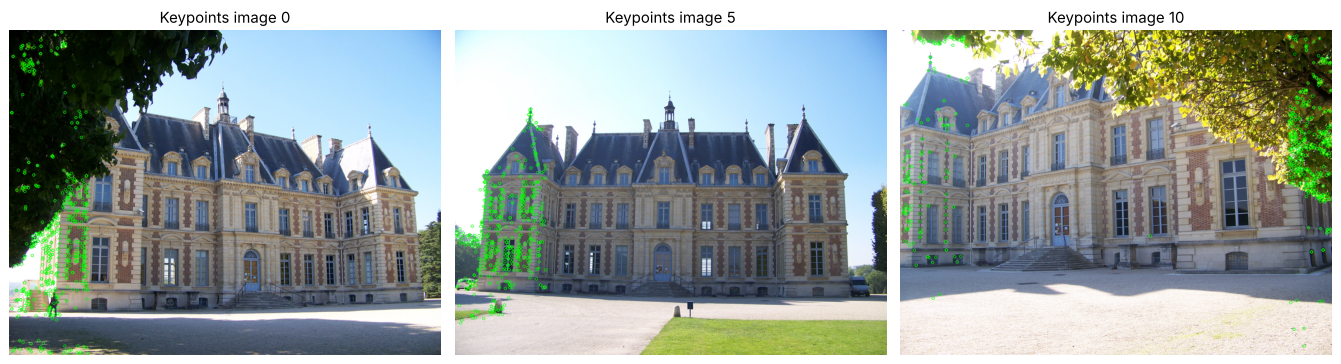

In [12]:
files = sorted(glob.glob("images/castle/*.JPG"))
SCALE = 0.35                                                        # work at ~990x745 for speed
K = np.loadtxt("images/castle/K.txt"); K[:2] *= SCALE
imgs = [cv2.resize(cv2.imread(f), None, fx=SCALE, fy=SCALE, interpolation=cv2.INTER_AREA) for f in files]
sift = cv2.SIFT_create(nfeatures=6000)
feats = [sift.detectAndCompute(cv2.cvtColor(im, cv2.COLOR_BGR2GRAY), None) for im in imgs]
kps = [np.float32([k.pt for k in kp]) for kp, _ in feats]
print("Intrinsics K (scaled):\n", np.round(K, 2))
for f, (kp, _) in zip(files, feats): print(f"{os.path.basename(f)}: {len(kp)} keypoints")
show([cv2.drawKeypoints(imgs[i], feats[i][0][:600], None, (0, 255, 0)) for i in (0, 5, 10)],
     ["Keypoints image 0", "Keypoints image 5", "Keypoints image 10"], size=5)

### Step 2: Match features across images (ratio test + geometric verification with RANSAC)

pair     raw  ratio-test  RANSAC-inliers
 0-1    4531     1187       1005
 0-2    4531      720        524
 0-3    4531      517        372
 1-2    3878     1453       1155
 1-3    3878     1081        866
 1-4    3878      776        601
 2-3    3450     1405       1210
 2-4    3450      969        788
 2-5    3450      700        481
 3-4    3082     1141        969
 3-5    3082      784        616
 3-6    3082      612        455
 4-5    3157     1114        896
 4-6    3157      751        581
 4-7    3157      610        421
 5-6    2599     1006        859
 5-7    2599      661        506
 5-8    2599      433        295
 6-7    2685      926        736
 6-8    2685      607        429
 6-9    2685      292        109
 7-8    3136      977        773
 7-9    3136      375        151
 7-10   3136      321        112
 8-9    2701      500        288
 8-10   2701      445        203
 9-10   2120      213        118


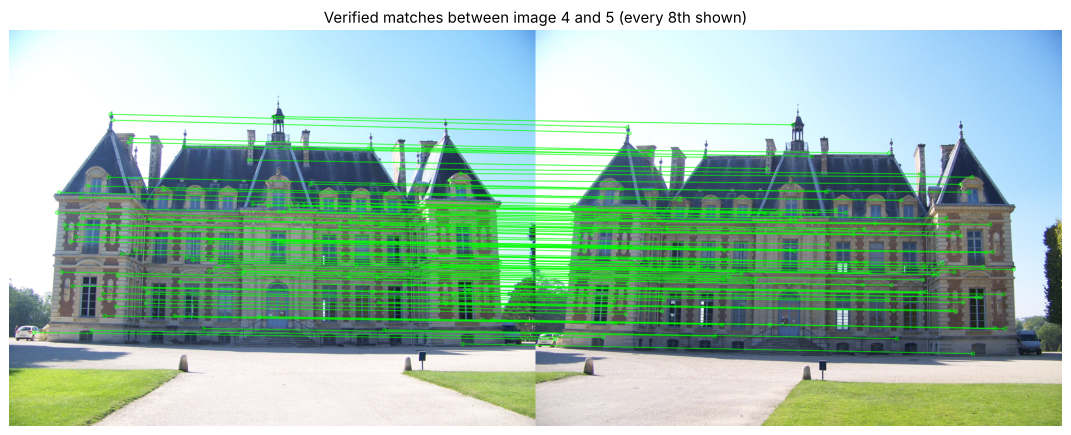

In [13]:
bf = cv2.BFMatcher(cv2.NORM_L2)
def match_pair(i, j):
    raw = bf.knnMatch(feats[i][1], feats[j][1], k=2)
    good = [a for a, b in raw if a.distance < 0.75 * b.distance]           # Lowe ratio test
    p1 = kps[i][[m.queryIdx for m in good]]; p2 = kps[j][[m.trainIdx for m in good]]
    E, mask = cv2.findEssentialMat(p1, p2, K, cv2.RANSAC, 0.999, 1.0)     # geometric verification
    keep = mask.ravel().astype(bool)
    return [(m.queryIdx, m.trainIdx) for m, k in zip(good, keep) if k], len(raw), len(good)

N = len(imgs)
matches = {}
print("pair     raw  ratio-test  RANSAC-inliers")
for i in range(N):
    for j in range(i+1, min(N, i+4)):                        # neighbouring views (sequential capture)
        m, nr, ng = match_pair(i, j)
        if len(m) >= 50: matches[(i, j)] = m
        print(f"{i:2d}-{j:<2d} {nr:6d} {ng:8d} {len(m):10d}")

i, j = 4, 5
mm = [cv2.DMatch(a, b, 0) for a, b in matches[(i, j)][::8]]
vis = cv2.drawMatches(imgs[i], feats[i][0], imgs[j], feats[j][0], mm, None, matchColor=(0, 255, 0), flags=2)
show([vis], [f"Verified matches between image {i} and {j} (every 8th shown)"], size=12)

### Step 3: Estimate camera poses (incremental SfM + bundle adjustment)

In [ ]:
from scipy.optimize import least_squares
from scipy.sparse import lil_matrix

poses, pts3d, colors, obs = {}, [], [], {}              # obs[(img, kp)] -> 3D point id
def Pmat(i): R, t = poses[i]; return K @ np.hstack([R, t])
def center(i): R, t = poses[i]; return (-R.T @ t).ravel()

def triangulate(i, j, pairs, max_err=2.0, min_angle=1.0):
    new = [(a, b) for a, b in pairs if (i, a) not in obs and (j, b) not in obs]
    if not new: return 0
    x1 = kps[i][[a for a, _ in new]]; x2 = kps[j][[b for _, b in new]]
    X = cv2.triangulatePoints(Pmat(i), Pmat(j), x1.T, x2.T); X = (X[:3] / X[3]).T
    added = 0
    for (a, b), x, u1, u2 in zip(new, X, x1, x2):
        good = True
        for k, u in ((i, u1), (j, u2)):
            R, t = poses[k]; xc = R @ x + t.ravel()
            if xc[2] <= 0 or np.linalg.norm((K @ xc)[:2] / xc[2] - u) > max_err: good = False; break
        r1, r2 = x - center(i), x - center(j)
        if not good or np.degrees(np.arccos(np.clip(r1 @ r2 / np.linalg.norm(r1) / np.linalg.norm(r2), -1, 1))) < min_angle:
            continue
        obs[(i, a)] = obs[(j, b)] = len(pts3d)
        pts3d.append(x); colors.append(imgs[i][int(u1[1]), int(u1[0])][::-1] / 255.0); added += 1
    return added

# initial pair
pairs01 = matches[(0, 1)]
p1, p2 = kps[0][[a for a, _ in pairs01]], kps[1][[b for _, b in pairs01]]
E, _ = cv2.findEssentialMat(p1, p2, K, cv2.RANSAC, 0.999, 1.0)
_, R, t, _ = cv2.recoverPose(E, p1, p2, K)
poses[0] = (np.eye(3), np.zeros((3, 1))); poses[1] = (R, t)
print("Initial pair 0-1:", triangulate(0, 1, pairs01), "points")

def bundle_adjust(max_nfev=20, max_err=4.0):
    # Jointly refine camera poses + 3D points (camera 0 fixed), then drop bad observations
    global pts3d
    cams_reg = sorted(poses); cmap = {c: n for n, c in enumerate(cams_reg)}
    keys = [k for k in obs if k[0] in poses]
    ci = np.array([cmap[k[0]] for k in keys]); pi = np.array([obs[k] for k in keys])
    uv = np.array([kps[i][a] for i, a in keys])
    P0 = np.array(pts3d); nc, npt = len(cams_reg), len(P0)
    x0 = np.hstack([np.r_[cv2.Rodrigues(poses[c][0])[0].ravel(), poses[c][1].ravel()] for c in cams_reg] + [P0.ravel()])
    def res(x):
        cams = x[:6*nc].reshape(nc, 6); P = x[6*nc:].reshape(npt, 3)
        out = np.empty((len(uv), 2))
        for c in range(nc):
            s = ci == c
            out[s] = cv2.projectPoints(P[pi[s]], cams[c, :3], cams[c, 3:], K, None)[0].reshape(-1, 2) - uv[s]
        return out.ravel()
    A = lil_matrix((2*len(uv), 6*nc + 3*npt), dtype=int); r = np.arange(len(uv))
    for k in range(6):
        A[2*r, 6*ci+k] = 1; A[2*r+1, 6*ci+k] = 1
    for k in range(3):
        A[2*r, 6*nc+3*pi+k] = 1; A[2*r+1, 6*nc+3*pi+k] = 1
    A[:, :6] = 0                                           # camera 0 fixed (gauge freedom)
    e0 = np.linalg.norm(res(x0).reshape(-1, 2), axis=1)
    sol = least_squares(res, x0, jac_sparsity=A, loss="huber", f_scale=1.0, x_scale="jac", max_nfev=max_nfev)
    e1 = np.linalg.norm(res(sol.x).reshape(-1, 2), axis=1)
    cams = sol.x[:6*nc].reshape(nc, 6)
    for c, n in cmap.items(): poses[c] = (cv2.Rodrigues(cams[n, :3])[0], cams[n, 3:].reshape(3, 1))
    pts3d = list(sol.x[6*nc:].reshape(npt, 3))
    for k, e in zip(keys, e1):                              # outlier observations removed
        if e > max_err: del obs[k]
    return np.median(e0), np.median(e1), len(keys)

# register remaining images (PnP), triangulate, and run bundle adjustment after each one
for j in range(2, N):
    prev = [i for i in range(j) if (i, j) in matches and i in poses]
    cand = {}
    for i in prev:
        for a, b in matches[(i, j)]:
            if (i, a) in obs: cand[b] = obs[(i, a)]
    bs = list(cand); X3 = np.float32([pts3d[cand[b]] for b in bs]); x2 = kps[j][bs]
    ok, rv, tv, inl = cv2.solvePnPRansac(X3, x2, K, None, reprojectionError=3.0, iterationsCount=3000)
    poses[j] = (cv2.Rodrigues(rv)[0], tv)
    for n in inl.ravel(): obs[(j, bs[n])] = cand[bs[n]]          # link only PnP inliers
    added = sum(triangulate(i, j, matches[(i, j)]) for i in prev)
    m0, m1, nobs = bundle_adjust(max_nfev=15)
    print(f"Image {j:2d}: PnP {len(inl):4d}/{len(X3):4d} inliers, +{added:4d} new points, "
          f"BA median error {m0:.2f} -> {m1:.2f} px")

m0, m1, nobs = bundle_adjust(max_nfev=60, max_err=2.0)        # final global bundle adjustment
m0, m1, nobs = bundle_adjust(max_nfev=30, max_err=2.0)
used = np.array(sorted(set(obs.values())))
pt_idx = np.array([obs[k] for k in obs])
uvo = np.array([kps[i][a] for i, a in obs])
errs = np.array([np.linalg.norm(cv2.projectPoints(pts3d[p][None], cv2.Rodrigues(poses[i][0])[0], poses[i][1], K, None)[0].ravel() - kps[i][a])
                 for (i, a), p in obs.items()])
track = np.bincount(pt_idx, minlength=len(pts3d))
valid = track >= 2
pts3d = np.array(pts3d)[valid]; colors = np.array(colors)[valid]
print(f"\nFinal model: {N} cameras, {len(pts3d)} points, {len(obs)} observations")
print(f"Re-projection error after global BA: mean {errs.mean():.3f} px, median {np.median(errs):.3f} px")
print("Mean track length (images per point): %.2f" % track[valid].mean())

Initial pair 0-1: 1005 points
Image  2: PnP  495/ 541 inliers, + 779 new points, BA median error 0.22 -> 0.21 px
Image  3: PnP  643/ 842 inliers, + 658 new points, BA median error 0.28 -> 0.28 px
Image  4: PnP  492/ 918 inliers, + 375 new points, BA median error 0.33 -> 0.34 px
Image  5: PnP  356/ 695 inliers, + 520 new points, BA median error 0.38 -> 0.41 px
Image  6: PnP  365/ 701 inliers, + 449 new points, BA median error 0.44 -> 0.46 px
Image  7: PnP  294/ 647 inliers, + 485 new points, BA median error 0.46 -> 0.45 px
Image  8: PnP  268/ 541 inliers, + 504 new points, BA median error 0.46 -> 0.46 px
Image  9: PnP  124/ 194 inliers, + 188 new points, BA median error 0.47 -> 0.47 px
Image 10: PnP  103/ 187 inliers, + 145 new points, BA median error 0.47 -> 0.48 px

Final model: 11 cameras, 4905 points, 12962 observations
Re-projection error after global BA: mean 0.557 px, median 0.479 px
Mean track length (images per point): 2.60


### Step 4: Construct the 3D scene: point cloud + mesh

Point cloud: 4886 points after outlier removal (from 4905)
Mesh: 4886 vertices, 7402 triangles
Saved castle_pointcloud.ply and castle_mesh.ply (open in MeshLab / CloudCompare / Open3D)


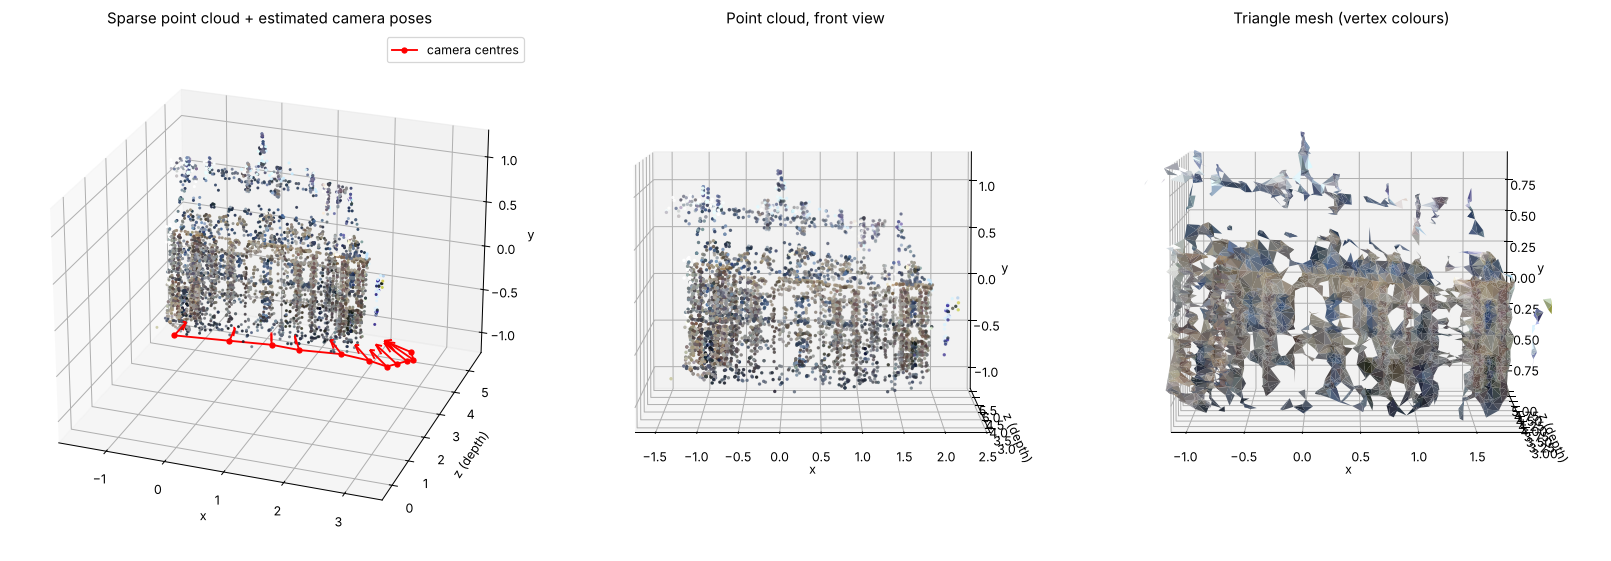

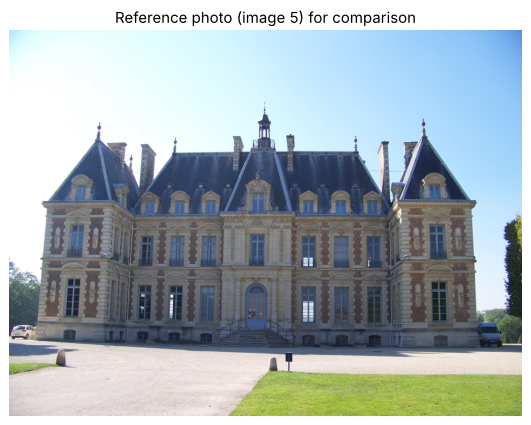

In [15]:
from scipy.spatial import Delaunay, cKDTree

# remove statistical outliers (distance to neighbours), as done before meshing
d, _ = cKDTree(pts3d).query(pts3d, k=9)
md_ = d[:, 1:].mean(1)
keep = md_ < md_.mean() + 1.5 * md_.std()
P, Cc = pts3d[keep], colors[keep]
print(f"Point cloud: {len(P)} points after outlier removal (from {len(pts3d)})")

# Mesh: Delaunay triangulation in the view of a central camera, drop triangles with long 3D edges
ref = N // 2
R, t = poses[ref]; xc = (R @ P.T + t).T; uvr = (K @ xc.T).T; uvr = uvr[:, :2] / uvr[:, 2:]
tri = Delaunay(uvr).simplices
edge = np.max([np.linalg.norm(P[tri[:, a]] - P[tri[:, b]], axis=1) for a, b in ((0, 1), (1, 2), (0, 2))], axis=0)
tri = tri[edge < 2 * np.median(edge)]
print(f"Mesh: {len(P)} vertices, {len(tri)} triangles")

def write_ply(path, V, Col, F=None):
    with open(path, "w") as f:
        f.write(f"ply\nformat ascii 1.0\nelement vertex {len(V)}\nproperty float x\nproperty float y\nproperty float z\n"
                "property uchar red\nproperty uchar green\nproperty uchar blue\n")
        if F is not None: f.write(f"element face {len(F)}\nproperty list uchar int vertex_indices\n")
        f.write("end_header\n")
        for v, c in zip(V, (Col * 255).astype(int)): f.write(f"{v[0]:.5f} {v[1]:.5f} {v[2]:.5f} {c[0]} {c[1]} {c[2]}\n")
        if F is not None:
            for a in F: f.write(f"3 {a[0]} {a[1]} {a[2]}\n")
write_ply("castle_pointcloud.ply", P, Cc)
write_ply("castle_mesh.ply", P, Cc, tri)
print("Saved castle_pointcloud.ply and castle_mesh.ply (open in MeshLab / CloudCompare / Open3D)")

# Plot: change to a y-up, z-forward view for display
cams_c = np.array([center(i) for i in range(N)])
def view(X): return np.c_[X[:, 0], X[:, 2], -X[:, 1]]
Pv, Cv = view(P), view(cams_c)

fig = plt.figure(figsize=(18, 6.5))
ax = fig.add_subplot(1, 3, 1, projection="3d")
ax.scatter(*Pv.T, c=Cc, s=2)
ax.plot(*Cv.T, "r-o", ms=4, label="camera centres")
for i in range(N):                                     # viewing direction of each camera
    dvec = view((poses[i][0].T @ np.array([0, 0, 1.0]))[None])[0]
    ax.quiver(*Cv[i], *dvec * 0.6, color="r")
ax.set_title("Sparse point cloud + estimated camera poses"); ax.legend(); ax.view_init(25, -70)

ax = fig.add_subplot(1, 3, 2, projection="3d")
ax.scatter(*Pv.T, c=Cc, s=3); ax.view_init(5, -90); ax.set_title("Point cloud, front view")

ax = fig.add_subplot(1, 3, 3, projection="3d")
fc = Cc[tri].mean(1)
ax.add_collection3d(Poly3DCollection(Pv[tri], facecolors=fc, edgecolor="none"))
lo, hi = np.percentile(Pv, 1, 0), np.percentile(Pv, 99, 0)
ax.set_xlim(lo[0], hi[0]); ax.set_ylim(lo[1], hi[1]); ax.set_zlim(lo[2], hi[2])
ax.view_init(5, -90); ax.set_title("Triangle mesh (vertex colours)")
for a in fig.axes: a.set_xlabel("x"); a.set_ylabel("z (depth)"); a.set_zlabel("y")
plt.tight_layout(); plt.show()

show([imgs[ref]], [f"Reference photo (image {ref}) for comparison"], size=6)